In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
from pathlib import Path

def find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "src" / "config.py").exists():
            return p
    raise FileNotFoundError("Could not find project root")

PROJECT_ROOT = find_project_root(Path.cwd())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from config import PROCESSED_DATA_DIR, IMAGES_DIR

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Load the clean data
df = pd.read_csv(PROCESSED_DATA_DIR / "clean_online_retail.csv", parse_dates=['invoice_date'])
print(f"Loaded {len(df)} rows.")

Loaded 397885 rows.


In [2]:
# 1. Find each customer's first purchase month (their Cohort Month)
df['order_month'] = df['invoice_date'].dt.to_period('M')
df['cohort_month'] = df.groupby('customer_id')['invoice_date'].transform('min').dt.to_period('M')

# 2. Calculate the "Cohort Index" (how many months since their first purchase)
df['cohort_index'] = (df['order_month'] - df['cohort_month']).apply(lambda x: x.n)

# 3. Count unique customers in each cohort for each month
cohort_data = df.groupby(['cohort_month', 'cohort_index'])['customer_id'].nunique().reset_index()

# 4. Pivot the data into a retention matrix
cohort_matrix = cohort_data.pivot(index='cohort_month', columns='cohort_index', values='customer_id')

# 5. Calculate retention rates (divide by the Month 0 total)
cohort_sizes = cohort_matrix.iloc[:, 0]
retention_matrix = cohort_matrix.divide(cohort_sizes, axis=0)

print("Cohort Retention Matrix (First 5 Rows):")
retention_matrix.head().round(3)

Cohort Retention Matrix (First 5 Rows):


cohort_index,0,1,2,3,4,5,6,7,8,9,10,11,12
cohort_month,,,,,,,,,,,,,
2010-12,1.0,0.366,0.323,0.384,0.363,0.398,0.363,0.349,0.354,0.395,0.374,0.503,0.266
2011-01,1.0,0.221,0.266,0.230,0.321,0.288,0.247,0.242,0.300,0.326,0.365,0.118,NaN
2011-02,1.0,0.187,0.187,0.284,0.271,0.247,0.253,0.279,0.247,0.305,0.068,NaN,NaN
2011-03,1.0,0.150,0.252,0.199,0.223,0.168,0.268,0.230,0.279,0.086,NaN,NaN,NaN
2011-04,1.0,0.213,0.203,0.210,0.197,0.227,0.217,0.260,0.073,NaN,NaN,NaN,NaN


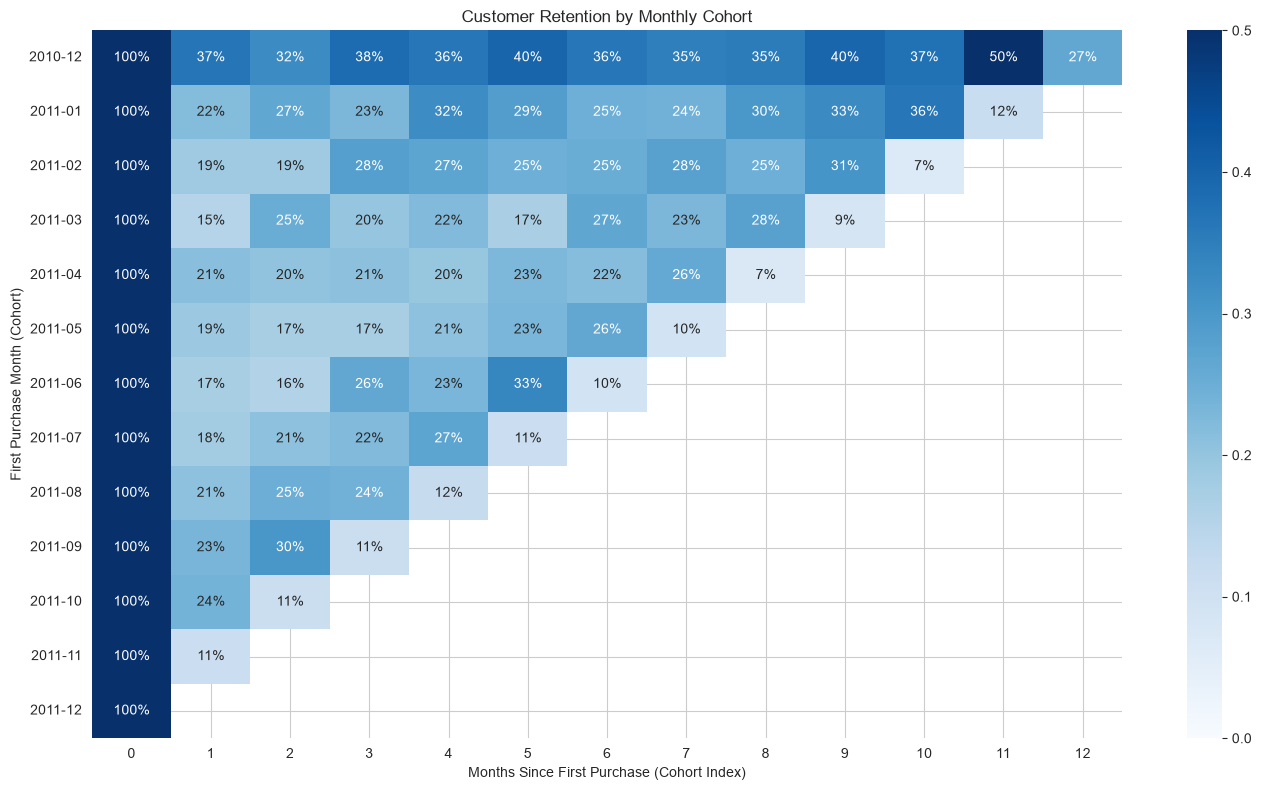

In [3]:
plt.figure(figsize=(14, 8))
sns.heatmap(retention_matrix, annot=True, fmt='.0%', cmap='Blues', vmin=0.0, vmax=0.5)
plt.title('Customer Retention by Monthly Cohort')
plt.xlabel('Months Since First Purchase (Cohort Index)')
plt.ylabel('First Purchase Month (Cohort)')
plt.tight_layout()
plt.savefig(IMAGES_DIR / "cohort_retention_heatmap.png", dpi=150)
plt.show()

In [4]:
# 1. Find the last purchase date for each customer
snapshot_date = df['invoice_date'].max() + pd.Timedelta(days=1)
last_purchase = df.groupby('customer_id')['invoice_date'].max().reset_index()

# 2. Calculate Recency (Days since last purchase)
last_purchase['recency_days'] = (snapshot_date - last_purchase['invoice_date']).dt.days

# 3. Define Churn (0 = Active, 1 = Churned)
# We use a 90-day threshold
last_purchase['churned'] = (last_purchase['recency_days'] > 90).astype(int)

# 4. Check the churn rate
churn_rate = last_purchase['churned'].mean()
print(f"Overall Churn Rate (90+ days inactive): {churn_rate:.1%}")

Overall Churn Rate (90+ days inactive): 33.4%


C:\Users\adebi\AppData\Local\Temp\ipykernel_10192\956337130.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=bucket_churn, x='order_bucket', y='churned', palette='Reds_r')


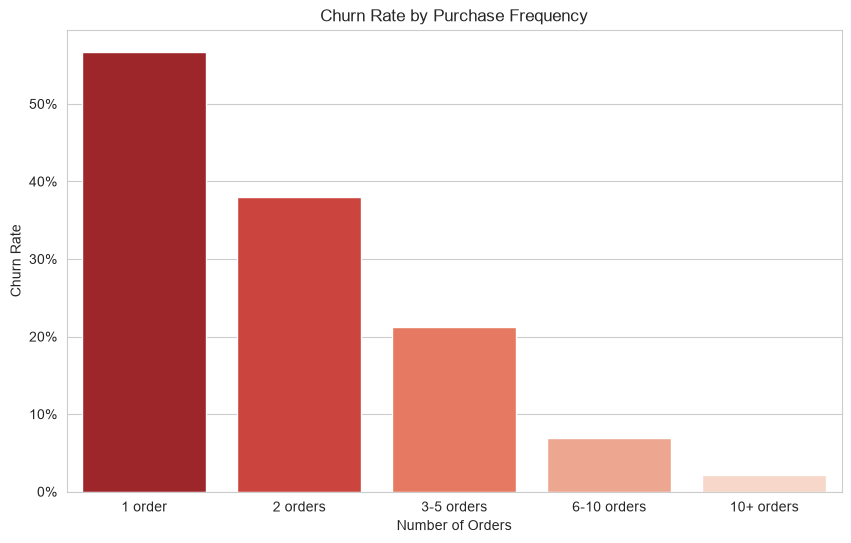

In [5]:
# 1. Calculate how many orders each customer made
orders_per_customer = df.groupby('customer_id')['invoice'].nunique().reset_index()
orders_per_customer.columns = ['customer_id', 'total_orders']

# 2. Merge with churn data
churn_analysis = last_purchase.merge(orders_per_customer, on='customer_id')

# 3. Create frequency buckets
churn_analysis['order_bucket'] = pd.cut(churn_analysis['total_orders'], 
                                        bins=[0, 1, 2, 5, 10, 100], 
                                        labels=['1 order', '2 orders', '3-5 orders', '6-10 orders', '10+ orders'])

# 4. Calculate churn rate by bucket
bucket_churn = churn_analysis.groupby('order_bucket')['churned'].mean().reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(data=bucket_churn, x='order_bucket', y='churned', palette='Reds_r')
plt.title('Churn Rate by Purchase Frequency')
plt.ylabel('Churn Rate')
plt.xlabel('Number of Orders')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0%}'.format(y)))
plt.savefig(IMAGES_DIR / "churn_by_frequency.png", dpi=150)
plt.show()

Average Order Value: £480.87
Average Customer Lifetime Value (Historical): £2054.27

Churned Customers: 1449
Estimated Lost Revenue Opportunity: £2,976,638.11


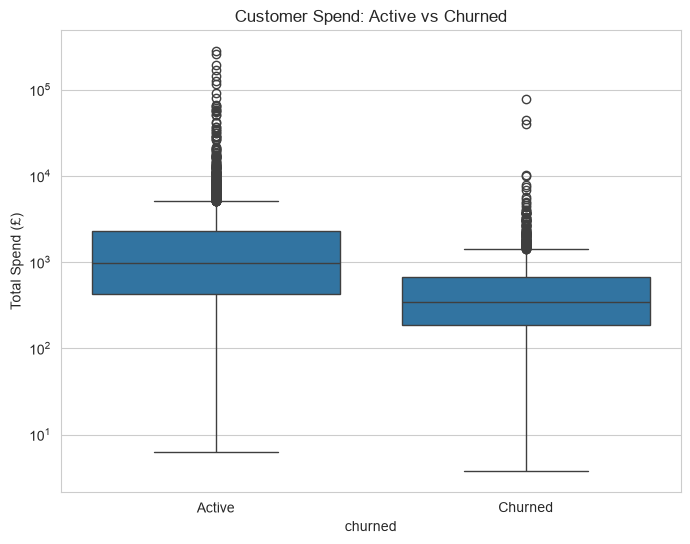


Median spend of Active Customers: £987.86
Median spend of Churned Customers: £349.55


In [6]:
# 1. Calculate the average value per purchase
avg_order_value = df['total_spend'].sum() / df['invoice'].nunique()
print(f"Average Order Value: £{avg_order_value:.2f}")

# 2. Calculate the average total spend per customer
customer_value = df.groupby('customer_id')['total_spend'].sum()
avg_customer_value = customer_value.mean()
print(f"Average Customer Lifetime Value (Historical): £{avg_customer_value:.2f}")

# 3. Estimate the value of churned customers
churned_customers = last_purchase[last_purchase['churned'] == 1]
num_churned = len(churned_customers)
lost_revenue_potential = num_churned * avg_customer_value

print(f"\nChurned Customers: {num_churned}")
print(f"Estimated Lost Revenue Opportunity: £{lost_revenue_potential:,.2f}")

# 4. Visualise Revenue by Churn Status
# Merge churn status back to spending
churn_analysis['total_spend'] = churn_analysis['customer_id'].map(customer_value)

plt.figure(figsize=(8, 6))
sns.boxplot(data=churn_analysis, x='churned', y='total_spend')
plt.xticks([0, 1], ['Active', 'Churned'])
plt.title('Customer Spend: Active vs Churned')
plt.ylabel('Total Spend (£)')
plt.yscale('log') # Log scale because spend is heavily skewed
plt.savefig(IMAGES_DIR / "spend_by_churn.png", dpi=150)
plt.show()

print("\nMedian spend of Active Customers: £{:,.2f}".format(churn_analysis[churn_analysis['churned']==0]['total_spend'].median()))
print("Median spend of Churned Customers: £{:,.2f}".format(churn_analysis[churn_analysis['churned']==1]['total_spend'].median()))